# Dept1: búsqueda híbrida, unión binaria y Erdős–Rényi p=0.5
Copia experimental del notebook Hamming. Conserva las 1,000 capas de Dept1, entropía espectral, unión binaria, cinco proyecciones, radio Hamming configurado y análisis unificado de diez corridas.

1. Solo las parejas originales permitidas por Hamming se evalúan al inicio.
2. Se elige el mínimo entre todas las distancias disponibles.
3. Tras unir dos grafos, el agregado recibe una firma usando las proyecciones, anchos y offsets originales (p_ER=0.5).
4. Se evalúa el agregado contra **todos** los clusters activos, aunque sus buckets no coincidan. Las distancias entre supervivientes siguen válidas y se reutilizan; se eliminan las asociadas a los clusters retirados.
5. Las parejas excluidas entre hojas originales siguen desconocidas. Si no hay candidatos, se habilita el fallback global. No es el baseline exhaustivo.

El motor mantiene candidatos mínimos por cluster y caché selectiva, sin necesidad de un heap adicional: selecciona el mismo mínimo disponible. El bucket de un agregado no restringe sus comparaciones. Todas las fusiones LSH reciben una firma real, también durante fallback. `global_mode` en Z identifica únicamente el fallback completo, no las comparaciones globales de agregados.

Diagnósticos: `restricted_merges` cuenta fusiones de hojas originales antes del fallback; `aggregate_global_merges`, fusiones con agregados antes del fallback; `global_merges`, fusiones durante fallback. `outside_bucket_merges` cuenta todas las fusiones fuera del radio Hamming. Los primeros tres contadores suman el total de fusiones.

Los pesos usados por clustering son 1; los conteos reales se conservan en `interaction_count` para actividad. La caché puede crecer cuadráticamente al añadir candidatos globales. No se presupone una mejora de tiempo o estabilidad. Resultados separados en `resultados_dept1_hibrido_er05_binary`. Reiniciar el kernel antes de ejecutar.


In [1]:
import numpy as np
import networkx as nx
from scipy.linalg import eig
from heapq import heappush, heappop
from collections import defaultdict
from tqdm import tqdm
import pandas as pd
import matplotlib.pyplot as plt
import time
import random
import os
import copy
from pathlib import Path
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# ----------------------------------------------------
# 1. Definición del Kernel de Frobenius para LSH
# ----------------------------------------------------

def projection_frobenius(A, B):
    return float(np.sum(A * B))

def hash_p_stable(projection, r, offset):
    if r <= 0:
        return 0
    return int(np.floor((projection + offset) / r))

def get_erdos_renyi_graph(n, p):
    while True:
        g = nx.erdos_renyi_graph(n, p)
        if g.number_of_edges() > 0:
            return g

def get_active_nodes(g):
    if 'active_nodes' in g.graph:
        return g.graph['active_nodes']
    nodes = sorted(list(set([n for n, d in g.degree() if d > 0])))
    g.graph['active_nodes'] = nodes
    return nodes

def get_adjacency(g, N):
    # Dense working array only; never retain one per input layer.
    A = nx.to_numpy_array(g, nodelist=range(N), weight='weight', dtype=float)
    np.fill_diagonal(A, 0)
    return A

def get_density_matrix(A):
    num_edges = np.sum(A) / 2.0
    if num_edges == 0:
        return np.zeros_like(A)
    degrees = np.sum(A, axis=1)
    L = np.diag(degrees) - A
    return L / (2.0 * num_edges)

def entropy_from_rho(rho):
    eigvals = np.linalg.eigvalsh(rho)
    eigvals[eigvals < 1e-12] = 0.0
    eigvals = eigvals[eigvals > 1e-12]
    return float(-np.sum(eigvals * np.log2(eigvals)))

def von_newmann_entropy(g, N_pad=None):
    if 'vn_entropy' in g.graph:
        return g.graph['vn_entropy']

    act = get_active_nodes(g)
    if len(act) == 0:
        entropy = 0.0
    else:
        A = nx.adjacency_matrix(g, nodelist=act, weight='weight').toarray().astype(float)
        sum_A = np.sum(A)
        L = np.diag(np.sum(A, axis=1)) - A
        rho = L / sum_A
        entropy = entropy_from_rho(rho)
        
    g.graph['vn_entropy'] = entropy
    return entropy

def aggregate(g1, g2, N=None):
    """Binary union: A_new[u,v] = 1 if either input contains the edge."""
    g = nx.Graph()
    g.add_nodes_from(g1.nodes())
    g.add_nodes_from(g2.nodes())
    for source in (g1, g2):
        for u, v in source.edges():
            g.add_edge(u, v, weight=1.0)
    if N is not None:
        g.add_nodes_from(range(N))
    return g


def js_divergence(g1, g2, N_pad=None):
    act1 = get_active_nodes(g1)
    act2 = get_active_nodes(g2)
    union_nodes = sorted(list(set(act1) | set(act2)))
    
    if len(union_nodes) == 0:
        return 0.0
        
    A1 = nx.adjacency_matrix(g1, nodelist=union_nodes, weight='weight').toarray().astype(float)
    A2 = nx.adjacency_matrix(g2, nodelist=union_nodes, weight='weight').toarray().astype(float)
    
    sum_A1 = np.sum(A1)
    sum_A2 = np.sum(A2)
    
    rho1 = (np.diag(np.sum(A1, axis=1)) - A1) / sum_A1 if sum_A1 > 0 else np.zeros_like(A1)
    rho2 = (np.diag(np.sum(A2, axis=1)) - A2) / sum_A2 if sum_A2 > 0 else np.zeros_like(A2)
    
    rho_mix = (rho1 + rho2) / 2.0
    
    h_mix = entropy_from_rho(rho_mix)
    h_avg = (von_newmann_entropy(g1) + von_newmann_entropy(g2)) / 2.0
    val = max(h_mix - h_avg, 0.0)
    return np.sqrt(val)

def get_bucket_id_for_graph(g, random_graphs, B, projection_ranges, N_pad, proj_func):
    bucket_id = ""
    A = get_density_matrix(get_adjacency(g, N_pad))

    for k, erg in enumerate(random_graphs):
        A_er = get_adjacency(erg, N_pad)
        proj = proj_func(A, A_er)

        min_proj, max_proj, offset = projection_ranges[k]
        r = (max_proj - min_proj) / B

        hash_bin = hash_p_stable(proj, r, offset)
        bucket_id += f"{hash_bin}_"

    return bucket_id

def quality(active, clusters, h_total=None, N_pad=None):
    active = list(active)
    if not active:
        return 0.0
    if h_total is None:
        N_pad = N_pad or max(clusters[i].number_of_nodes() for i in active)
        total = np.zeros((N_pad, N_pad))
        for i in active:
            add_density(total, clusters[i])
        h_total = entropy_from_rho(total / len(active))
    return 0.0 if h_total <= 1e-12 else float(
        1 - sum(von_newmann_entropy(clusters[i]) for i in active) / len(active) / h_total)

def get_rho_sub(g):
    act = get_active_nodes(g)
    if len(act) == 0:
        return np.zeros((1, 1))
    A = nx.adjacency_matrix(g, nodelist=act, weight='weight').toarray().astype(float)
    sum_A = np.sum(A)
    return (np.diag(np.sum(A, axis=1)) - A) / sum_A if sum_A > 0 else np.zeros_like(A)


def has_bucket_candidates(bucket_members, active):
    for members in bucket_members.values():
        alive = [x for x in members if x in active]
        if len(alive) >= 2:
            return True
    return False

# ----------------------------------------------------
# 2. Controladores LSH-HLA y Baseline
# ----------------------------------------------------

def build_lsh_buckets(graphs, num_proj, B, proj_func, p_er=0.5):
    num_graphs = len(graphs)
    N_pad = max(g.number_of_nodes() for g in graphs)

    bucket_ids = [""] * num_graphs
    random_graphs = []
    projection_ranges = []

    for k in range(num_proj):
        erg = get_erdos_renyi_graph(N_pad, p_er)
        random_graphs.append(erg)
        A_er = get_adjacency(erg, N_pad)

        projections = []
        for g in graphs:
            A = get_density_matrix(get_adjacency(g, N_pad))
            proj = proj_func(A, A_er)
            projections.append(proj)

        min_proj = min(projections)
        max_proj = max(projections)
        r = (max_proj - min_proj) / B
        offset = np.random.uniform(0, r) if r > 0 else 0.0
        projection_ranges.append((min_proj, max_proj, offset))
        for i in range(num_graphs):
            hash_bin = hash_p_stable(projections[i], r, offset)
            bucket_ids[i] += f"{hash_bin}_"

    buckets = defaultdict(list)
    for i, bid in enumerate(bucket_ids):
        buckets[bid].append(i)

    return buckets, bucket_ids, random_graphs, projection_ranges

def hierarchical_bucket_heap_dynamic(graphs, buckets, bucket_ids, random_graphs,
                                     projection_ranges, B, proj_func, epsilon=np.inf):
    return memory_bounded_hierarchy(
        graphs, epsilon=epsilon, bucket_ids=bucket_ids,
        rehash=lambda g: get_bucket_id_for_graph(
            g, random_graphs, B, projection_ranges,
            graphs[0].number_of_nodes(), proj_func))

def shclust_heap_dynamic(graphs, num_proj=3, B=10, proj_func=projection_frobenius, epsilon=np.inf):
    buckets, bucket_ids, random_graphs, projection_ranges = build_lsh_buckets(
        graphs,
        num_proj=num_proj,
        B=B,
        proj_func=proj_func
    )

    Z, clusters, active, bucket_members = hierarchical_bucket_heap_dynamic(
        graphs=graphs,
        buckets=buckets,
        bucket_ids=bucket_ids,
        random_graphs=random_graphs,
        projection_ranges=projection_ranges,
        B=B,
        proj_func=proj_func,
        epsilon=epsilon
    )

    return Z, clusters, active, bucket_members, bucket_ids

def hierarchical_clustering_heap(graphs, epsilon=np.inf):
    """Exact global minimum, with one nearest candidate per active cluster."""
    Z, clusters, active, _ = memory_bounded_hierarchy(graphs, epsilon=epsilon)
    return Z, clusters, active

# Helper functions for evaluation
def get_cluster_memberships(Z, num_graphs, target_merges):
    memberships = {i: [i] for i in range(num_graphs)}
    active = set(range(num_graphs))
    
    for step in range(min(target_merges, len(Z))):
        row = Z[step]
        c_i = int(row[0])
        c_j = int(row[1])
        new_id = int(row[4])
        
        memberships[new_id] = memberships.pop(c_i) + memberships.pop(c_j)
        active.remove(c_i)
        active.remove(c_j)
        active.add(new_id)
        
    return {c: memberships[c] for c in active}

def get_cluster_labels(Z, num_graphs, k_star):
    cluster_members = get_cluster_memberships(Z, num_graphs, k_star)
    labels = np.zeros(num_graphs, dtype=int)
    for c_idx, (c_id, members) in enumerate(cluster_members.items()):
        for m in members:
            labels[m] = c_idx
    return labels
def elbow_method(q):
    """
    Método del codo basado en distancia perpendicular a la recta
    entre (1, q(1)) y (m, q(m)).
    """
    q = np.asarray(q, dtype=float)
    m = len(q)

    x1, y1 = 1, q[0]
    x2, y2 = m, q[-1]

    dx = x2 - x1
    dy = y2 - y1

    norm = np.sqrt(dx**2 + dy**2)

    distances = np.zeros(m)
    for i in range(m):
        x0 = i + 1
        y0 = q[i]
        area = abs(dy * (x0 - x1) - dx * (y0 - y1))
        distances[i] = area / norm

    k_star = int(np.argmax(distances) + 1)
    return k_star, distances


def fresh_graphs(graphs):
    """Reset numerical caches without duplicating immutable graph topology."""
    for g in graphs:
        for key in ('adjacency', 'active_nodes', 'vn_entropy'):
            g.graph.pop(key, None)
    return list(graphs)


def add_density(total, g, factor=1.0):
    """Accumulate a normalized Laplacian using edges, without a dense copy."""
    weight_sum = sum(d.get('weight', 1.0) for u, v, d in g.edges(data=True) if u != v)
    if weight_sum <= 0:
        return
    scale = factor / (2.0 * weight_sum)
    for u, v, d in g.edges(data=True):
        if u == v:
            continue
        w = d.get('weight', 1.0) * scale
        total[u, u] += w
        total[v, v] += w
        total[u, v] -= w
        total[v, u] -= w


def memory_bounded_hierarchy(graphs, epsilon=np.inf, bucket_ids=None, rehash=None):
    """Exact minimum among allowed pairs; sparse on-demand distance cache.

    Outside-bucket pairs remain unknown until needed, not assumed distant.
    Global fallback may still require quadratic storage in active clusters.
    """
    radius = BUCKET_NEIGHBOR_RADIUS
    if isinstance(radius, (bool, np.bool_)) or not isinstance(radius, (int, np.integer)) or radius < 0:
        raise ValueError('BUCKET_NEIGHBOR_RADIUS debe ser un entero no negativo')
    radius = int(radius)
    diagnostics = dict(distance_evaluations=0, cache_hits=0, peak_cached_pairs=0,
                       restricted_merges=0, neighboring_bucket_merges=0,
                       global_merges=0, global_start_clusters=None,
                       aggregate_global_merges=0, outside_bucket_merges=0)
    memory_bounded_hierarchy.last_diagnostics = diagnostics
    if not graphs:
        return [], {}, set(), defaultdict(set)
    n = len(graphs)
    N = graphs[0].number_of_nodes()
    clusters = dict(enumerate(graphs))
    active = set(clusters)
    bids = dict(enumerate(bucket_ids)) if bucket_ids is not None else {}
    def signature(bid):
        return tuple(map(int, bid.strip('_').split('_'))) if isinstance(bid, str) else tuple(bid)

    bucket_index = defaultdict(set)
    signatures = {i: signature(bid) for i, bid in bids.items()}
    if signatures and len({len(sig) for sig in signatures.values()}) != 1:
        raise ValueError('Las firmas deben tener la misma dimensión')

    # Match all coordinates except up to radius positions.
    # Omitting exactly min(radius, dimension) positions also finds closer pairs.
    from itertools import combinations
    wildcard_index = defaultdict(set)

    def wildcard_keys(sig):
        for omitted in combinations(range(len(sig)), min(radius, len(sig))):
            omitted_set = set(omitted)
            yield (omitted, tuple(value for axis, value in enumerate(sig) if axis not in omitted_set))

    def index_add(i, sig):
        bucket_index[sig].add(i)
        if radius:
            for key in wildcard_keys(sig):
                wildcard_index[key].add(i)

    def index_remove(i, sig):
        bucket_index[sig].discard(i)
        if not bucket_index[sig]:
            del bucket_index[sig]
        if radius:
            for key in wildcard_keys(sig):
                wildcard_index[key].discard(i)
                if not wildcard_index[key]:
                    del wildcard_index[key]

    for i, sig in signatures.items():
        index_add(i, sig)

    def candidate_ids(i):
        if global_mode or i >= n:
            return active - {i}
        sig = signatures[i]
        result = set(bucket_index.get(sig, ()))
        if radius:
            for key in wildcard_keys(sig):
                result.update(wildcard_index.get(key, ()))
        result.update(j for j in active if j >= n)
        result.discard(i)
        return result

    distance_cache = {}
    cached_neighbors = defaultdict(set)

    def discard_cached(i):
        for j in cached_neighbors.pop(i, set()):
            distance_cache.pop((min(i, j), max(i, j)), None)
            cached_neighbors[j].discard(i)

    global_mode = bucket_ids is None
    nearest = {}
    rho_sum = np.zeros((N, N), dtype=float)
    for g in tqdm(graphs, desc="Acumulando matrices de densidad"):
        add_density(rho_sum, g)
    Z = []

    def allowed(i, j):
        return i != j and (global_mode or i >= n or j >= n or sum(a != b for a,b in zip(signatures[i], signatures[j])) <= radius)

    def candidate(i, j):
        # Stable tie-breaking independent of set traversal.
        a, b = sorted((i, j))
        key = (a, b)
        if USE_DISTANCE_CACHE and key in distance_cache:
            diagnostics['cache_hits'] += 1
            return distance_cache[key], a, b
        distance = js_divergence(clusters[a], clusters[b])
        diagnostics['distance_evaluations'] += 1
        if USE_DISTANCE_CACHE:
            distance_cache[key] = distance
            cached_neighbors[a].add(b)
            cached_neighbors[b].add(a)
            diagnostics['peak_cached_pairs'] = max(diagnostics['peak_cached_pairs'], len(distance_cache))
        return distance, a, b

    def refresh(i):
        best = None
        for j in sorted(candidate_ids(i)):
            if allowed(i, j):
                value = candidate(i, j)
                if best is None or value < best:
                    best = value
        nearest[i] = best

    for i in tqdm(sorted(active), desc="Buscando candidatos (caché bajo demanda)"):
        refresh(i)
    progress = tqdm(total=max(n - 1, 0), desc="Fusiones")
    try:
        while len(active) > 1:
            candidates = [v for v in nearest.values() if v is not None]
            if not candidates:
                if global_mode:
                    break
                diagnostics['global_start_clusters'] = len(active)
                global_mode = True
                for i in sorted(active):
                    refresh(i)
                continue
            dist, i, j = min(candidates)
            if dist > epsilon:
                break
            same_bucket = bucket_ids is not None and bids[i] == bids[j]
            if global_mode:
                diagnostics['global_merges'] += 1
            elif i >= n or j >= n:
                diagnostics['aggregate_global_merges'] += 1
            else:
                diagnostics['restricted_merges'] += 1
            if bucket_ids is not None:
                hamming_distance = sum(a != b for a, b in zip(signatures[i], signatures[j]))
                if hamming_distance > radius:
                    diagnostics['outside_bucket_merges'] += 1
                elif not same_bucket:
                    diagnostics['neighboring_bucket_merges'] += 1
            merged = aggregate(clusters[i], clusters[j], N)
            add_density(rho_sum, clusters[i], -1.0)
            add_density(rho_sum, clusters[j], -1.0)
            add_density(rho_sum, merged)
            new_id = n + len(Z)
            for old in (i, j):
                discard_cached(old)
                if bucket_ids is not None:
                    sig = signatures.pop(old)
                    index_remove(old, sig)
                active.remove(old)
                del clusters[old]
                del nearest[old]
            clusters[new_id] = merged
            active.add(new_id)
            if bucket_ids is not None:
                bids[new_id] = rehash(merged)
                signatures[new_id] = signature(bids[new_id])
                index_add(new_id, signatures[new_id])
            h_total = entropy_from_rho(rho_sum / len(active))
            q = quality(active, clusters, h_total=h_total, N_pad=N)
            row = [i, j, dist, q, new_id]
            if bucket_ids is not None:
                row += [bids[new_id], same_bucket, global_mode]
            Z.append(row)
            for other in sorted(active - {new_id}):
                old_best = nearest[other]
                if old_best is not None and (i in old_best[1:] or j in old_best[1:]):
                    refresh(other)
                elif allowed(other, new_id):
                    value = candidate(other, new_id)
                    if old_best is None or value < old_best:
                        nearest[other] = value
            refresh(new_id)
            if bucket_ids is not None:
                del bids[i], bids[j]
            progress.update(1)
    finally:
        progress.close()
    members = defaultdict(set)
    if bucket_ids is not None:
        for i in active:
            members[bids[i]].add(i)
    return Z, clusters, active, members


USE_DISTANCE_CACHE = True
BUCKET_NEIGHBOR_RADIUS = 0  # Entero >= 0: número máximo de coordenadas distintas


In [2]:
# ----------------------------------------------------
# Carga de Datos y Segmentación Multiplex (Día-Hora)
# ----------------------------------------------------

# Intervalo relativo al origen del registro; fin exclusivo.
START_DAY = 0
START_HOUR = 0
END_DAY = None  # Opcional: acotar el intervalo antes de limitar capas.
END_HOUR = 0
MAX_LAYERS = 1000  # None permite todas las horas activas del intervalo.

file_path = "data/TemporalEmail/email-Eu-core-temporal-Dept1.txt"

print("Cargando datos desde", file_path, "...")
raw_data = np.loadtxt(file_path, dtype=np.int64)

total_emails = len(raw_data)
original_node_ids = np.unique(raw_data[:, :2])
num_nodes = len(original_node_ids)
node_to_index = {int(node): i for i, node in enumerate(original_node_ids)}

print(f"Total de correos (interacciones): {total_emails}")
print(f"Total de nodos (usuarios únicos): {num_nodes}")

# Una ventana por hora absoluta desde el origen del registro.
# Las horas sin interacciones entre usuarios distintos no generan grafos.
ts = raw_data[:, 2]
if np.any(ts < 0):
    raise ValueError("Se esperan timestamps no negativos")
hour_indices = ts // 3600
valid = raw_data[:, 0] != raw_data[:, 1]
valid_events = raw_data[valid]
valid_hours = hour_indices[valid]
order = np.argsort(valid_hours, kind="stable")
sorted_events = valid_events[order]
active_hours, starts, counts = np.unique(valid_hours[order], return_index=True, return_counts=True)
print(f"Capas horarias activas en todo Dept1: {len(active_hours)}")
if START_DAY < 0 or not 0 <= START_HOUR < 24 or not 0 <= END_HOUR < 24:
    raise ValueError("Usa días no negativos y horas entre 0 y 23")
start_hour = START_DAY * 24 + START_HOUR
end_hour = END_DAY * 24 + END_HOUR if END_DAY is not None else int(hour_indices.max()) + 1
if end_hour <= start_hour:
    raise ValueError("El fin debe ser posterior al inicio")
if MAX_LAYERS is not None and (not isinstance(MAX_LAYERS, int) or MAX_LAYERS <= 0):
    raise ValueError("MAX_LAYERS debe ser un entero positivo o None")
selected = np.flatnonzero((active_hours >= start_hour) & (active_hours < end_hour))
if MAX_LAYERS is not None:
    selected = selected[:MAX_LAYERS]
if not len(selected):
    raise ValueError("El intervalo no contiene interacciones válidas")
active_hours, starts, counts = active_hours[selected], starts[selected], counts[selected]
selected_end_hour = min(end_hour, int(active_hours[-1]) + 1)
combinations = [(int(t // 24), int(t % 24)) for t in active_hours]
print(f"Capas seleccionadas: {len(active_hours)}; interacciones: {int(counts.sum())}")
print(f"Intervalo relativo [inicio, fin): día {start_hour // 24}, {start_hour % 24:02d}:00 "
      f"a día {selected_end_hour // 24}, {selected_end_hour % 24:02d}:00")
print(f"Horas sin interacciones omitidas: {selected_end_hour - start_hour - len(active_hours)}")
if MAX_LAYERS is not None and len(active_hours) < MAX_LAYERS:
    print("El intervalo tiene menos horas activas que MAX_LAYERS; se usan todas las disponibles.")
selection_metadata = {
    "start_hour": int(start_hour), "end_hour_exclusive": int(selected_end_hour),
    "layers": int(len(active_hours)), "events": int(counts.sum()),
    "global_users": int(num_nodes),
}

graphs = []
for absolute_hour, start, count in zip(active_hours, starts, counts):
    d, h = divmod(int(absolute_hour), 24)
    chunk = sorted_events[start:start + count]

    g = nx.Graph()
    # Asegurar que todos tengan el mismo conjunto de nodos
    g.add_nodes_from(range(num_nodes))
    g.graph['absolute_hour'] = int(absolute_hour)
    g.graph['start_seconds'] = int(absolute_hour) * 3600
    g.graph['end_seconds'] = (int(absolute_hour) + 1) * 3600
    g.graph['day'] = d
    g.graph['hour'] = h
    g.graph['event_count'] = int(np.count_nonzero(chunk[:, 0] != chunk[:, 1]))
    
    for u, v, _ in chunk:
        u, v = node_to_index[int(u)], node_to_index[int(v)]
        if u == v:
            continue
        if g.has_edge(u, v):
            g[u][v]['interaction_count'] += 1
        else:
            g.add_edge(u, v, weight=1.0, interaction_count=1)
            
    graphs.append(g)

print(f"Segmentación multiplex completada. Se crearon {len(graphs)} grafos (capas).")
print(f"  Ejemplo: Capa 0 -> Día {graphs[0].graph['day']}, Hora {graphs[0].graph['hour']:02d}:00 | Aristas: {graphs[0].number_of_edges()}")

assert all(set(g) == set(range(num_nodes)) for g in graphs)
assert all(g.number_of_edges() > 0 for g in graphs)
selected_users = np.unique(np.concatenate([sorted_events[start:start + count, :2].ravel() for start, count in zip(starts, counts)]))
print(f"Investigadores con actividad en el intervalo seleccionado: {len(selected_users)}")

assert all(d["weight"] == 1.0 for g in graphs for _, _, d in g.edges(data=True))


Cargando datos desde data/TemporalEmail/email-Eu-core-temporal-Dept1.txt ...
Total de correos (interacciones): 61046
Total de nodos (usuarios únicos): 309
Capas horarias activas en todo Dept1: 6186
Capas seleccionadas: 1000; interacciones: 8539
Intervalo relativo [inicio, fin): día 0, 00:00 a día 98, 14:00
Horas sin interacciones omitidas: 1366
Segmentación multiplex completada. Se crearon 1000 grafos (capas).
  Ejemplo: Capa 0 -> Día 0, Hora 00:00 | Aristas: 1
Investigadores con actividad en el intervalo seleccionado: 255


In [3]:
len(graphs)

1000

### 2.1. Visualización de un Subgrafo de la Red (Nodos 0 a 9)
Para mostrar de forma legible la topología de la red sin saturación, visualizamos un subgrafo inducido de los primeros 10 nodos (0 a 9) en el **Snapshot 0** con el estilo de red solicitado.


/tmp/ipykernel_1308430/1411088031.py:22: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


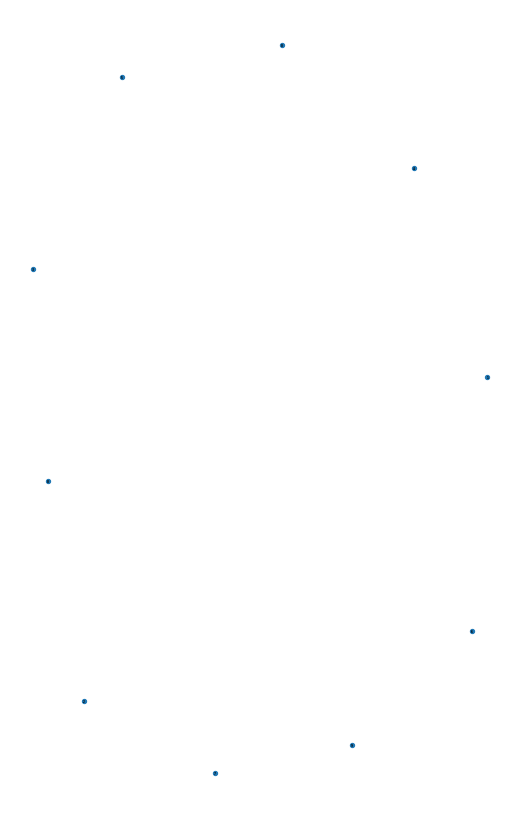

In [4]:
# Obtener el subgrafo inducido de los nodos 0 a 9 en el Snapshot 0
g_sub = graphs[0].subgraph(range(min(10, num_nodes))).copy()

# Calcular distribución espacial
pos = nx.spring_layout(g_sub, seed=42)

# Dibujar con el estilo exacto de la imagen de referencia
plt.figure(figsize=(5, 8), facecolor="white")
nx.draw(
    g_sub,
    pos,
    with_labels=True,
    node_color="#1f77b4",     # Color azul estándar de la imagen
    node_size=8,            # Nodos grandes
    font_weight="bold",       # Texto en negrita
    font_size=2,             # Letra grande
    font_color="black",       # Texto negro dentro de los nodos
    width=0.5,                # Aristas gruesas y negras
    edge_color="black"
)
plt.axis("off")
plt.tight_layout()
plt.show()

### Usuarios del Departamento 1
Todos los usuarios de este archivo pertenecen a Dept1. Se conserva su ID local y no se cruza con IDs de la red completa.


In [5]:
df_investigators_depts = pd.DataFrame({
    "Investigador_ID": original_node_ids,
    "Indice_Matriz": range(num_nodes),
    "Departamento_Principal": "Departamento 1",
})
for g in graphs:
    nx.set_node_attributes(g, {i: int(u) for i, u in enumerate(original_node_ids)}, "original_id")
    nx.set_node_attributes(g, "Departamento 1", "departamento")
df_investigators_depts.to_csv("data/TemporalEmail/investigador_departamento_dept1_hibrido_er05_binary.csv", index=False)
print(df_investigators_depts["Departamento_Principal"].value_counts())


Departamento_Principal
Departamento 1    309
Name: count, dtype: int64


## Experimentos unificados
Orden: diez corridas B=40 con tabla y curvas; diez baseline; diez por B=10,40,80,300 reutilizando B=40; interpretación temporal. Se guardan fusiones, membresías, curvas y tiempos por corrida, y se puede reanudar. No se reportan ARI ni NMI. Las desviaciones son muestrales. Los tiempos excluyen preparación y exportaciones.


In [6]:
import hashlib
import json

EXPERIMENT_RUNS = 10
EXPERIMENT_PROJECTIONS = 5
EXPERIMENT_B_VALUES = [10, 40, 80, 300]
FORCE_EXPERIMENTS = False
implementation = ''.join(json.loads(Path('shclust-temporal-email-dept1-hamming-hibrido-er05.ipynb').read_text())['cells'][1]['source'])
fingerprint = hashlib.sha256(implementation.encode())
fingerprint.update(repr((USE_DISTANCE_CACHE, BUCKET_NEIGHBOR_RADIUS, EXPERIMENT_PROJECTIONS)).encode())
for g in graphs:
    fingerprint.update(repr((tuple(sorted(g.nodes())), g.graph.get('absolute_hour'),
        sorted((min(u,v),max(u,v),float(d.get('weight',1))) for u,v,d in g.edges(data=True)))).encode())
experiment_dir = Path('data/TemporalEmail/resultados_dept1_hibrido_er05_binary/experimentos') / fingerprint.hexdigest()[:20]
experiment_dir.mkdir(parents=True, exist_ok=True)
experiment_results = {}


def run_series(method, B=None):
    key = (method, B)
    if key in experiment_results:
        return experiment_results[key]
    name = 'baseline' if B is None else f'LSH_B{B}'
    series = []
    for run in range(EXPERIMENT_RUNS):
        seed = 42 + run
        path = experiment_dir / f'{name}_run{run+1:02d}.npz'
        if path.exists() and not FORCE_EXPERIMENTS:
            with np.load(path, allow_pickle=False) as saved:
                z = saved['z'].copy()
                labels = saved['labels'].copy()
                row = json.loads(str(saved['row']))
            print(f'{name}, corrida {run+1}: recuperada; tiempo de la ejecución original.')
        else:
            print(f'{name}, corrida {run+1}/{EXPERIMENT_RUNS}...', flush=True)
            inputs = fresh_graphs(graphs)
            numpy_state, python_state = np.random.get_state(), random.getstate()
            try:
                np.random.seed(seed)
                random.seed(seed)
                begin = time.perf_counter()
                if B is None:
                    z_raw, _, _ = hierarchical_clustering_heap(inputs)
                    elapsed = time.perf_counter()-begin
                    buckets = None
                else:
                    z_raw, _, _, _, ids = shclust_heap_dynamic(inputs, num_proj=EXPERIMENT_PROJECTIONS, B=B)
                    elapsed = time.perf_counter()-begin
                    buckets = len(set(ids))
                diagnostics = dict(memory_bounded_hierarchy.last_diagnostics)
            finally:
                np.random.set_state(numpy_state)
                random.setstate(python_state)
            z = np.asarray([r[:5] for r in z_raw], dtype=float)
            if z.shape != (len(graphs)-1,5):
                raise ValueError('Jerarquía incompleta')
            cut, _ = elbow_method(z[:,3])
            labels = get_cluster_labels(z, len(graphs), cut)
            row = dict(method=method, B=B, run=run+1, seed=seed,
                clusters=len(graphs)-cut, aggregation_step=cut, initial_buckets=buckets,
                q_at_elbow=float(z[cut-1,3]), seconds=elapsed, **diagnostics)
            np.savez_compressed(path,z=z,labels=labels,row=json.dumps(row))
        if z.shape != (len(graphs)-1,5) or labels.shape != (len(graphs),):
            raise ValueError('Archivo guardado incompatible')
        # Exportar los integrantes de cada cluster con su día y hora.
        memberships = pd.DataFrame({'layer':np.arange(len(graphs)), 'cluster':labels,
            'day':[g.graph['day'] for g in graphs], 'hour':[g.graph['hour'] for g in graphs]})
        memberships.to_csv(experiment_dir / f'{name}_run{run+1:02d}_clusters.csv',index=False)
        series.append(dict(row=row,z=z,labels=labels))
        pd.DataFrame([r['row'] for r in series]).to_csv(experiment_dir / f'{name}_runs.csv',index=False)
    experiment_results[key] = series
    return series


def show_series(series, name):
    table = pd.DataFrame([r['row'] for r in series])
    columns = ['run','seed','clusters','aggregation_step','initial_buckets','q_at_elbow','seconds']
    print(table[columns].to_string(index=False))
    summary = table[['clusters','aggregation_step','initial_buckets','q_at_elbow','seconds']].astype(float).agg(['mean','std']).T
    print(summary.to_string())
    summary.to_csv(experiment_dir / f'{name}_summary.csv')
    fig, ax = plt.subplots(figsize=(12,7))
    for i, result in enumerate(series):
        q = result['z'][:,3]
        cut = result['row']['aggregation_step']
        color = plt.get_cmap('tab10')(i%10)
        ax.plot(np.arange(1,len(q)+1),q,color=color,label=f"Corrida {i+1} (k*={cut}, clusters={result['row']['clusters']})")
        ax.scatter(cut,q[cut-1],color=color,s=35,zorder=5)
    ax.set(xlabel='Aggregation step',ylabel='q(C)',title=f'{name} — Dept1')
    ax.grid(alpha=.3)
    ax.legend(bbox_to_anchor=(1.02,1),loc='upper left',fontsize=8)
    fig.tight_layout()
    fig.savefig(experiment_dir / f'{name}_quality.png',dpi=180,bbox_inches='tight')
    fig.savefig(experiment_dir / f'{name}_quality.pdf',bbox_inches='tight')
    plt.show()
    pd.DataFrame({f'run_{i+1}':r['z'][:,3] for i,r in enumerate(series)},
        index=np.arange(1,len(graphs))).rename_axis('aggregation_step').to_csv(experiment_dir / f'{name}_quality.csv')
    return table

### 1. Diez corridas B=40 y sus diez curvas de calidad


LSH_B40, corrida 1/10...


Fusiones: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 999/999 [23:36<00:00,  1.42s/it]

LSH_B40, corrida 2/10...



Fusiones: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 999/999 [23:58<00:00,  1.44s/it]

LSH_B40, corrida 3/10...


...

LSH_B40, corrida 9/10...



Fusiones: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 999/999 [22:18<00:00,  1.34s/it]

LSH_B40, corrida 10/10...



Fusiones: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 999/999 [22:47<00:00,  1.37s/it]


 run  seed  clusters  aggregation_step  initial_buckets  q_at_elbow     seconds
   1    42        40               960              724    0.938503 1419.002084
   2    43        38               962              733    0.939051 1441.771925
   3    44        37               963              736    0.933079 1432.783124
   4    45        41               959              726    0.940281 1581.283268
   5    46        40               960              739    0.947469 1535.297971
   6    47        34               966              733    0.936801 1508.571207
   7    48        37               963              733    0.942458 1534.766307
   8    49        34               966              727    0.936619 1381.960622
   9    50        36               964              719    0.930267 1341.483297
  10    51        33               967              733    0.934010 1370.059896
                         mean        std
clusters            37.000000   2.788867
aggregation_step   963.000000   2.7888

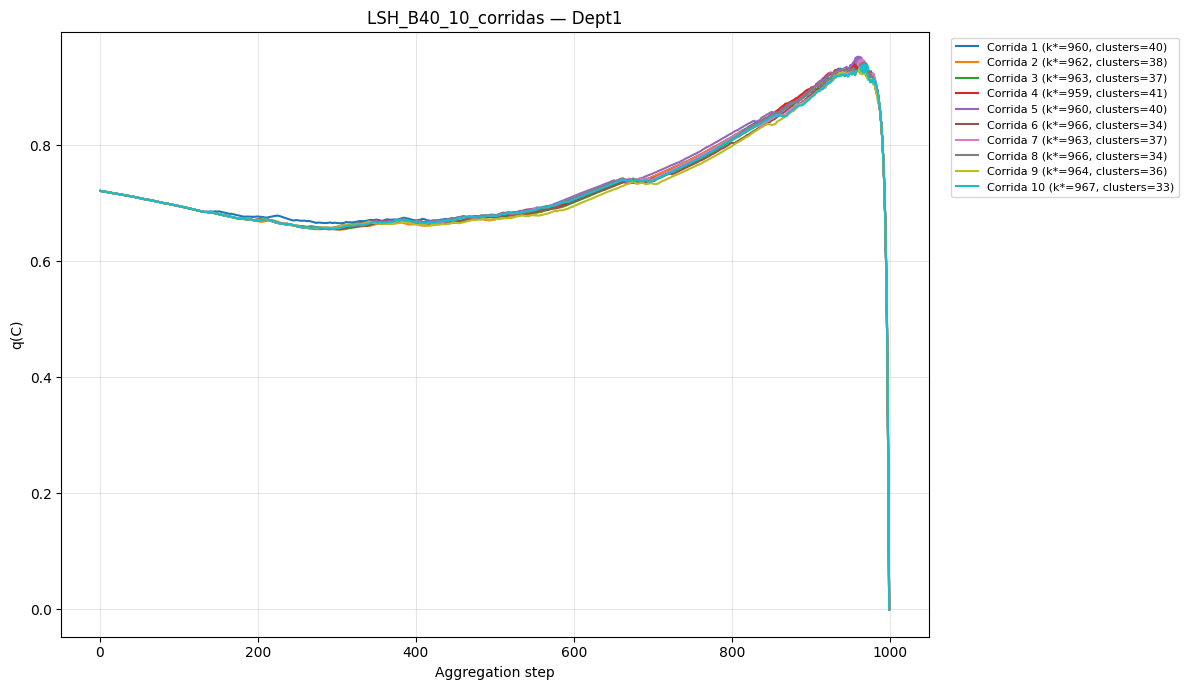

In [7]:
series_B40 = run_series('LSH', 40)
df_stability_temp = show_series(series_B40, 'LSH_B40_10_corridas')

### 2. Diez corridas del baseline


baseline, corrida 1/10...


Fusiones: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 999/999 [09:30<00:00,  1.75it/s]

baseline, corrida 2/10...



Fusiones: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 999/999 [09:32<00:00,  1.74it/s]

baseline, corrida 3/10...


...

baseline, corrida 9/10...



Fusiones: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 999/999 [09:27<00:00,  1.76it/s]


baseline, corrida 10/10...


Fusiones: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 999/999 [09:30<00:00,  1.75it/s]


 run  seed  clusters  aggregation_step initial_buckets  q_at_elbow    seconds
   1    42        14               986            None    0.866183 861.274113
   2    43        14               986            None    0.866183 864.775004
   3    44        14               986            None    0.866183 861.416113
   4    45        14               986            None    0.866183 859.969015
   5    46        14               986            None    0.866183 862.757833
   6    47        14               986            None    0.866183 863.390242
   7    48        14               986            None    0.866183 865.673477
   8    49        14               986            None    0.866183 858.883518
   9    50        14               986            None    0.866183 858.070849
  10    51        14               986            None    0.866183 860.002456
                        mean           std
clusters           14.000000  0.000000e+00
aggregation_step  986.000000  0.000000e+00
initial_bucke

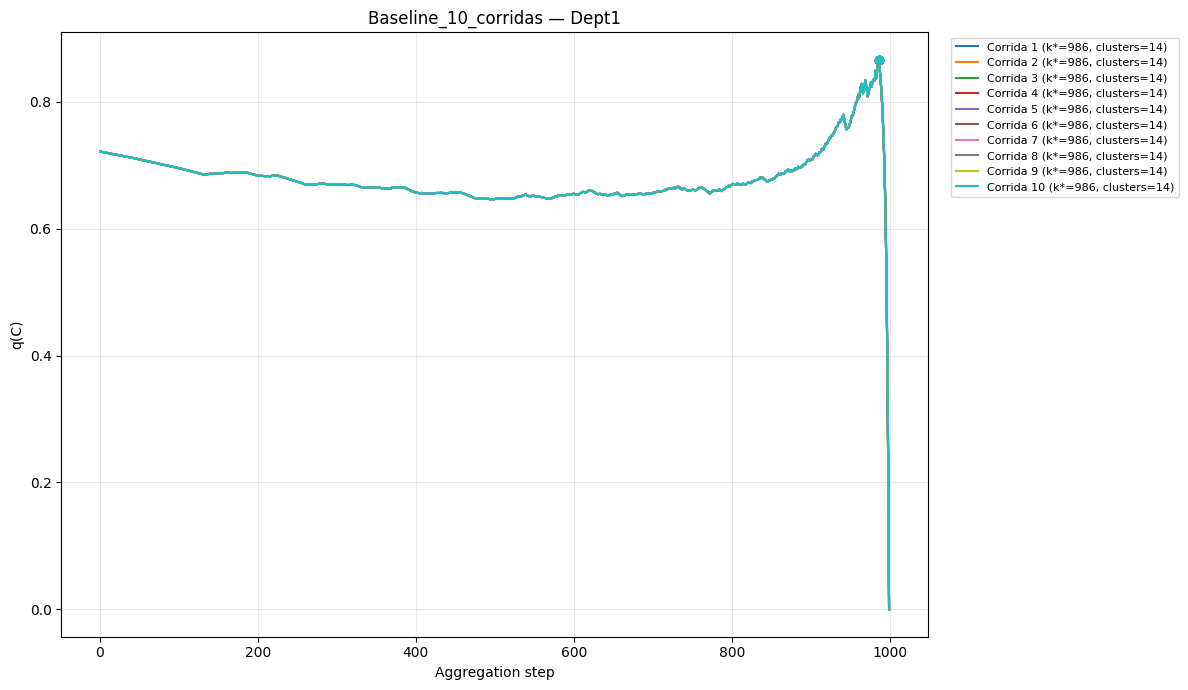

In [8]:
series_baseline = run_series('Baseline')
df_baseline_runs = show_series(series_baseline, 'Baseline_10_corridas')

### 3. Sensibilidad a B y comparación de curvas


In [9]:
sensitivity_rows = []
for B in EXPERIMENT_B_VALUES:
    series = run_series('LSH', B)  # B=40 reutiliza exactamente las diez corridas previas.
    table = pd.DataFrame([r['row'] for r in series])
    summary = {'B':B}
    for metric in ['clusters','aggregation_step','initial_buckets','q_at_elbow','seconds']:
        summary[f'{metric}_mean'] = table[metric].mean()
        summary[f'{metric}_std'] = table[metric].std(ddof=1)
    sensitivity_rows.append(summary)
df_sensitivity_temp = pd.DataFrame(sensitivity_rows)
print(df_sensitivity_temp.to_string(index=False))
df_sensitivity_temp.to_csv(experiment_dir / 'sensibilidad.csv',index=False)
fig, axes = plt.subplots(1,3,figsize=(15,4))
for ax, metric, title in zip(axes,['clusters','seconds','q_at_elbow'],['Clusters seleccionados','Tiempo (s)','q en el codo']):
    ax.errorbar(df_sensitivity_temp.B,df_sensitivity_temp[f'{metric}_mean'],
        yerr=df_sensitivity_temp[f'{metric}_std'],marker='o',capsize=4)
    ax.set(xlabel='B',ylabel=title,xscale='log')
    ax.grid(alpha=.3)
fig.tight_layout()
fig.savefig(experiment_dir / 'sensibilidad.png',dpi=180)
plt.show()
# Curvas ilustrativas: misma semilla 42 para todas las configuraciones.
fig, ax = plt.subplots(figsize=(12,7))
styles = {10:('#ffa0a0',':','o'),40:('#ff6060','--','s'),80:('#d00000','-.','^'),300:('#800000','-','D')}
for label, result, color, style, marker in [('Baseline',series_baseline[0],'black','-','o')] + [
    (f'LSH B={B}',experiment_results[('LSH',B)][0],*styles[B]) for B in EXPERIMENT_B_VALUES]:
    q=result['z'][:,3];cut=result['row']['aggregation_step']
    ax.plot(np.arange(1,len(q)+1),q,color=color,linestyle=style,
        label=f"{label} (k*={cut}, clusters={result['row']['clusters']})")
    ax.scatter(cut,q[cut-1],color=color,marker=marker,s=70,zorder=5)
ax.set(xlabel='Aggregation step',ylabel='q(C)',title='Baseline vs LSH variando B — Dept1, semilla 42')
ax.legend(fontsize=9);ax.grid(alpha=.3);fig.tight_layout()
fig.savefig(experiment_dir / 'comparacion_B.png',dpi=180)
fig.savefig(experiment_dir / 'comparacion_B.pdf')
plt.show()

LSH_B10, corrida 1/10...


Fusiones: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 999/999 [22:50<00:00,  1.37s/it]

LSH_B10, corrida 2/10...



Fusiones: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 999/999 [23:01<00:00,  1.38s/it]

LSH_B10, corrida 3/10...


...

LSH_B300, corrida 3/10...



Fusiones: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 999/999 [23:11<00:00,  1.39s/it]

LSH_B300, corrida 4/10...



Fusiones:  41%|█████████████████████████████████████████████████████████████████████████████████████████████████████████▍                                                                                                                                                          | 405/999 [05:19<07:48,  1.27it/s]


KeyboardInterrupt: 

In [ ]:
# Interpretación de las primeras corridas ya calculadas; no se repite clustering.
Z_baseline = series_baseline[0]['z']
Z_lsh = series_B40[0]['z']
labels_baseline = series_baseline[0]['labels']
labels_lsh = series_B40[0]['labels']
k_star_normal = series_baseline[0]['row']['aggregation_step']
k_star_lsh = series_B40[0]['row']['aggregation_step']

In [ ]:
def show_temporal_clusters(labels, method_name):
    print(f"\nClusters de ventanas horarias ({method_name})")
    for cluster_id in sorted(set(labels)):
        members = np.flatnonzero(labels == cluster_id)
        phases = [(int(graphs[i].graph['day']), int(graphs[i].graph['hour'])) for i in members]
        print(f"Cluster {cluster_id}: {len(members)} capas; (día relativo, hora relativa): {phases}")
show_temporal_clusters(labels_baseline, "Baseline")
show_temporal_clusters(labels_lsh, "LSH-HLA")

## Interpretación temporal, actividad y departamentos
El mapa día × hora muestra los clusters como categorías: gris indica horas sin interacciones y blanco posiciones fuera del intervalo. Los IDs de clusters son propios de cada método; un mismo número no implica correspondencia entre baseline y LSH.

Los perfiles departamentales describen los clusters, no son clases predichas. Se cuenta una participación por extremo de cada interacción: un mensaje entre departamentos aporta una a cada uno. Se compara el promedio de proporciones por hora con la proporción ponderada por actividad, incluyendo Otros en el denominador. Sin asignaciones verificadas se omite esta figura.

La tabla por capa incluye usuarios activos, conexiones distintas, interacciones, densidad sobre el conjunto global de usuarios, cobertura de etiquetas entre usuarios activos y departamento conocido predominante (con empates explícitos). Su proporción se calcula sobre toda la participación, incluida Otros. Las interacciones con algún extremo Otros se contabilizan aparte; no se atribuyen a comunicación interna o entre departamentos.

Se exportan figuras PNG y tablas CSV en `data/TemporalEmail/resultados_dept1_hibrido_er05_binary/analisis_temporal/`.


In [ ]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch


def layer_activity_table(graphs, labels):
    """Department participation counts message endpoints (two per interaction)."""
    if len(graphs) != len(labels):
        raise ValueError("Se requiere una etiqueta por capa")
    rows, profiles = [], []
    for layer, (g, cluster) in enumerate(zip(graphs, labels)):
        active = [u for u, degree in g.degree() if degree > 0]
        departments = {u: str(g.nodes[u].get('departamento', 'Otros')).strip() or 'Otros'
                       for u in active}
        participation = defaultdict(float)
        events = internal = external = unknown = 0.0
        for u, v, data in g.edges(data=True):
            w = float(data.get('interaction_count', data.get('weight', 1)))
            events += w
            a, b = departments[u], departments[v]
            participation[a] += w
            participation[b] += w
            if 'Otros' in (a, b):
                unknown += w
            elif a == b:
                internal += w
            else:
                external += w
        total = sum(participation.values())
        known = {d: w for d, w in participation.items() if d != 'Otros'}
        largest = max(known.values(), default=0)
        winners = sorted(d for d, w in known.items() if w == largest)
        dominant = winners[0] if len(winners) == 1 else ('Empate' if winners else 'Sin asignación')
        rows.append(dict(layer=layer, day=int(g.graph['day']), hour=int(g.graph['hour']),
                         cluster=int(cluster), active_users=len(active), interactions=events,
                         edges=g.number_of_edges(),
                         density=nx.density(g),
                         label_coverage=sum(d != 'Otros' for d in departments.values()) / len(active) if active else 0,
                         dominant_department=dominant,
                         dominant_share=largest / total if total else 0,
                         internal_interactions=internal, external_interactions=external,
                         unknown_department_interactions=unknown))
        for department, weight in participation.items():
            profiles.append(dict(layer=layer, cluster=int(cluster), department=department,
                                 participation=weight, share=weight / total if total else 0))
    return pd.DataFrame(rows), pd.DataFrame(profiles)


def temporal_cluster_grid(table, start_hour, end_hour):
    """-2 outside interval; -1 empty hour; nonnegative categorical cluster codes."""
    first_day, last_day = start_hour // 24, (end_hour - 1) // 24
    hours = np.arange(first_day * 24, (last_day + 1) * 24).reshape(-1, 24)
    grid = np.where((hours >= start_hour) & (hours < end_hour), -1, -2)
    cluster_ids = sorted(table.cluster.unique())
    codes = {cluster: i for i, cluster in enumerate(cluster_ids)}
    for row in table.itertuples():
        grid[row.day - first_day, row.hour] = codes[row.cluster]
    return grid, first_day, cluster_ids


def plot_temporal_analysis(graphs, labels, method, selection, output_dir):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    table, profiles = layer_activity_table(graphs, labels)
    table.to_csv(output_dir / f'{method}_capas.csv', index=False)
    summary = table.groupby('cluster').agg(
        layers=('layer', 'size'), mean_active_users=('active_users', 'mean'),
        total_interactions=('interactions', 'sum'), mean_interactions=('interactions', 'mean'),
        mean_edges=('edges', 'mean'), mean_density=('density', 'mean'),
        mean_label_coverage=('label_coverage', 'mean'),
        internal_interactions=('internal_interactions', 'sum'),
        external_interactions=('external_interactions', 'sum'),
        unknown_department_interactions=('unknown_department_interactions', 'sum'))
    summary.to_csv(output_dir / f'{method}_clusters.csv')
    print(f'\nActividad por cluster — {method}')
    print(summary.to_string())

    grid, first_day, cluster_ids = temporal_cluster_grid(
        table, selection['start_hour'], selection['end_hour_exclusive'])
    palette = plt.get_cmap('tab20', max(1, len(cluster_ids)))
    colors = ['white', '#dedede'] + [palette(i) for i in range(len(cluster_ids))]
    cmap = ListedColormap(colors)
    norm = BoundaryNorm(np.arange(-2.5, len(cluster_ids) + .5), len(colors))
    fig, ax = plt.subplots(figsize=(13, max(5, min(16, len(grid) * .18))))
    ax.imshow(grid, cmap=cmap, norm=norm, aspect='auto', interpolation='nearest')
    ticks = np.unique(np.linspace(0, len(grid) - 1, min(20, len(grid)), dtype=int))
    ax.set_yticks(ticks, ticks + first_day)
    ax.set_xticks(range(24))
    ax.set(xlabel='Hora relativa', ylabel='Día relativo', title=f'Cluster por ventana horaria — {method}')
    handles = [Patch(facecolor=colors[0], edgecolor='gray', label='Fuera del intervalo'),
               Patch(facecolor=colors[1], label='Sin interacciones')]
    handles += [Patch(facecolor=colors[i + 2], label=f'Cluster {c}') for i, c in enumerate(cluster_ids)]
    ax.legend(handles=handles, bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
    fig.tight_layout()
    fig.savefig(output_dir / f'{method}_dia_hora.png', dpi=180, bbox_inches='tight')
    plt.show()

    if profiles.empty or not (profiles.department != 'Otros').any():
        print('Perfil departamental omitido: no hay departamentos verificados; todas las etiquetas son Otros.')
        return table, summary

    # Fill missing layer/department combinations with zero before averaging.
    shares = profiles.pivot(index='layer', columns='department', values='share').fillna(0)
    hourly = shares.groupby(table.set_index('layer')['cluster']).mean()
    totals = profiles.groupby(['cluster', 'department']).participation.sum().unstack(fill_value=0)
    weighted = totals.div(totals.sum(axis=1), axis=0)
    weighted = weighted.reindex(index=hourly.index, columns=hourly.columns, fill_value=0)
    hourly.to_csv(output_dir / f'{method}_departamentos_promedio_hora.csv')
    weighted.to_csv(output_dir / f'{method}_departamentos_ponderados.csv')
    fig, axes = plt.subplots(1, 2, figsize=(14, max(4, len(hourly) * .3)), constrained_layout=True)
    for ax, matrix, title in zip(axes, [hourly, weighted],
                                ['Igual peso por hora', 'Ponderado por interacciones']):
        im = ax.imshow(matrix.values, vmin=0, vmax=1, cmap='Blues', aspect='auto')
        ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=45, ha='right')
        ax.set_yticks(range(len(matrix)), matrix.index)
        ax.set(title=title, xlabel='Departamento', ylabel='Cluster')
    fig.colorbar(im, ax=axes, label='Proporción de participación (extremos de interacciones)')
    fig.suptitle(f'Perfil departamental — {method}')
    fig.savefig(output_dir / f'{method}_cluster_departamento.png', dpi=180, bbox_inches='tight')
    plt.show()
    return table, summary


analysis_output_dir = Path('data/TemporalEmail/resultados_dept1_hibrido_er05_binary/analisis_temporal')
activity_baseline, summary_baseline = plot_temporal_analysis(
    graphs, labels_baseline, 'baseline', selection_metadata, analysis_output_dir)
activity_lsh, summary_lsh = plot_temporal_analysis(
    graphs, labels_lsh, 'lsh', selection_metadata, analysis_output_dir)


## Prueba opcional de las dos mejoras sobre 30 capas


In [ ]:
# Prueba controlada sobre las primeras 30 capas, sin ejecutar todo el dataset.
# Ejecutar después de cargar funciones y grafos. No depende del baseline completo.
probe_graphs = graphs[:30]
probe_rows = []
probe_merges = {}
previous_cache, previous_radius = USE_DISTANCE_CACHE, BUCKET_NEIGHBOR_RADIUS
numpy_state, python_state = np.random.get_state(), random.getstate()
try:
    for radius in (0, 1):
        for cache in (False, True):
            USE_DISTANCE_CACHE, BUCKET_NEIGHBOR_RADIUS = cache, radius
            np.random.seed(42)
            random.seed(42)
            inputs = fresh_graphs(probe_graphs)
            begin = time.perf_counter()
            z_probe, _, _, _, _ = shclust_heap_dynamic(inputs, num_proj=5, B=40)
            elapsed = time.perf_counter() - begin
            probe_merges[(radius, cache)] = [row[:5] for row in z_probe]
            probe_rows.append(dict(radius=radius, cache=cache, layers=len(inputs), seconds=elapsed,
                                   **memory_bounded_hierarchy.last_diagnostics))
        np.testing.assert_allclose(probe_merges[(radius, False)], probe_merges[(radius, True)])
finally:
    USE_DISTANCE_CACHE, BUCKET_NEIGHBOR_RADIUS = previous_cache, previous_radius
    np.random.set_state(numpy_state)
    random.setstate(python_state)
probe_results = pd.DataFrame(probe_rows)
print(probe_results.to_string(index=False))
Path('data/TemporalEmail/resultados_dept1_hibrido_er05_binary').mkdir(exist_ok=True)
probe_results.to_csv('data/TemporalEmail/resultados_dept1_hibrido_er05_binary/prueba_30_capas.csv', index=False)
